# Probe set overlap: Visium vs Chromium Flex

Are the Visium (spatial) and Chromium Flex (snRNA) probe sets the same panel?

1. Which probe set each SpaceRanger / CellRanger run used (from `web_summary.html` under `data/`).
2. Sequence overlap between the published 10x probe sets.

Outputs: `figs/technical/probe_overlap/`

In [1]:
import re
from pathlib import Path
from urllib.request import urlretrieve

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.R").exists())
PROBE_DIR = ROOT / "data/other/external_references/probe_sets"
OUT_DIR = ROOT / "figs/technical/probe_overlap"
PROBE_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

URL = "https://cf.10xgenomics.com/supp/"
PROBE_SETS = {
    "Visium Human v1.0":     "spatial-exp/probeset/Visium_Human_Transcriptome_Probe_Set_v1.0_GRCh38-2020-A.csv",
    "Visium Human v2.0":     "spatial-exp/probeset/Visium_Human_Transcriptome_Probe_Set_v2.0_GRCh38-2020-A.csv",
    "Chromium Human v1.0.1": "cell-exp/probeset/Chromium_Human_Transcriptome_Probe_Set_v1.0.1_GRCh38-2020-A.csv",
    "Chromium Human v1.1.0": "cell-exp/probeset/Chromium_Human_Transcriptome_Probe_Set_v1.1.0_GRCh38-2024-A.csv",
    "Visium Mouse v1.0":     "spatial-exp/probeset/Visium_Mouse_Transcriptome_Probe_Set_v1.0_mm10-2020-A.csv",
    "Visium Mouse v2.0":     "spatial-exp/probeset/Visium_Mouse_Transcriptome_Probe_Set_v2.0_mm10-2020-A.csv",
    "Chromium Mouse v1.0.1": "cell-exp/probeset/Chromium_Mouse_Transcriptome_Probe_Set_v1.0.1_mm10-2020-A.csv",
}

## 1. Probe set versions used

Empty if SpaceRanger / CellRanger outputs are not unpacked under `data/`.

In [2]:
def pipeline_info(html):
    txt = html.read_text(errors="ignore")
    get = lambda key: (m := re.search(rf'\["{key}",\s*"([^"]*)"', txt)) and m.group(1)
    return {"run": html.parent.name, "probe_set": get("Probe Set Name"),
            "pipeline": get("Pipeline Version"), "chemistry": get("Chemistry")}

runs = pd.DataFrame([pipeline_info(f) for f in sorted(ROOT.glob("data/**/web_summary.html"))])
runs if len(runs) else "No web_summary.html under data/ (unpack the Zenodo deposit first)"

'No web_summary.html under data/ (unpack the Zenodo deposit first)'

## 2. Load probe sets (downloaded from 10x if missing)

In [3]:
def load(name):
    f = PROBE_DIR / Path(PROBE_SETS[name]).name
    if not f.exists():
        urlretrieve(URL + PROBE_SETS[name], f)
    return pd.read_csv(f, comment="#")

probes = {name: load(name) for name in PROBE_SETS}

pd.DataFrame({name: {"probes": len(p),
                     "probes included": p.included.sum(),
                     "genes included": p.gene_id[p.included].nunique()}
              for name, p in probes.items()}).T

,probes,probes included,genes included
Visium Human v1.0,20259,19008,18308
Visium Human v2.0,54580,53504,18085
Chromium Human v1.0.1,54580,53444,18082
Chromium Human v1.1.0,54580,53459,18129
Visium Mouse v1.0,21178,20057,19758
Visium Mouse v2.0,55538,55187,19059
Chromium Mouse v1.0.1,55538,55128,19059


## 3. Sequence overlap between all panels

Cell = shared probe sequences as % of the union of both panels.

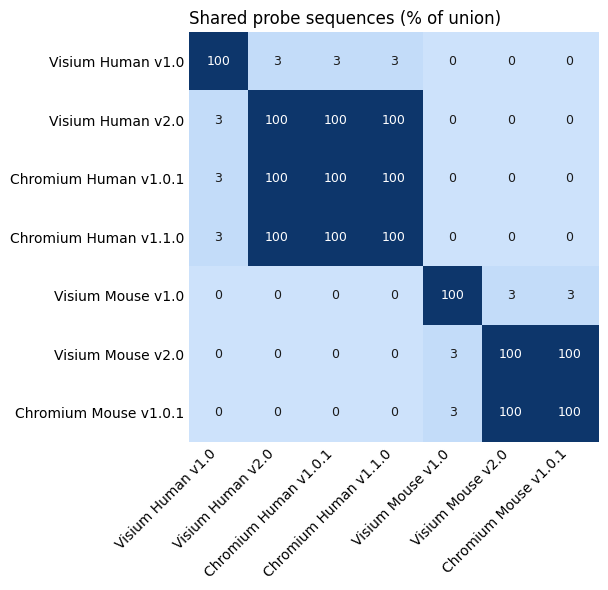

In [4]:
names = list(probes)
seqs = {n: set(probes[n].probe_seq) for n in names}
overlap = pd.DataFrame([[100 * len(seqs[a] & seqs[b]) / len(seqs[a] | seqs[b]) for b in names] for a in names],
                       index=names, columns=names)
overlap.round(1).to_csv(OUT_DIR / "sequence_overlap_pct.csv")

blues = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(overlap, cmap=blues, vmin=0, vmax=100)
for i in range(len(names)):
    for j in range(len(names)):
        v = overlap.iat[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9, color="white" if v > 50 else "#1a1a1a")
ax.set_xticks(range(len(names)), names, rotation=45, ha="right")
ax.set_yticks(range(len(names)), names)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Shared probe sequences (% of union)", loc="left")
fig.tight_layout()
fig.savefig(OUT_DIR / "sequence_overlap_heatmap.pdf")
plt.show()

## 4. Visium v2.0 vs Chromium Flex v1.0.1

Same sequences — what differs? Probes matched by sequence, compared on probe ID and `included`.

In [5]:
for species in ["Human", "Mouse"]:
    v, c = probes[f"Visium {species} v2.0"], probes[f"Chromium {species} v1.0.1"]
    m = v.merge(c, on="probe_seq", suffixes=("_visium", "_flex"))
    diff = m[(m.probe_id_visium != m.probe_id_flex) | (m.included_visium != m.included_flex)]
    genes_v, genes_c = set(v.gene_id[v.included]), set(c.gene_id[c.included])
    only_v = v[v.gene_id.isin(genes_v - genes_c)].probe_id.str.split("|").str[1].unique()
    print(f"{species}: {len(m)} shared sequences, {len(diff)} with different ID/flag "
          f"({diff.probe_id_flex.str.startswith('DEPRECATED_').sum()} marked DEPRECATED_ in Flex)")
    print(f"  genes measured: {len(genes_v & genes_c)} both, Visium only {sorted(only_v)}, "
          f"Flex only {len(genes_c - genes_v)}")
    diff.to_csv(OUT_DIR / f"differing_probes_{species.lower()}.csv", index=False)

Human: 54580 shared sequences, 61 with different ID/flag (61 marked DEPRECATED_ in Flex)
  genes measured: 18082 both, Visium only ['GABARAPL2', 'SLC39A4', 'TKT'], Flex only 0
Mouse: 55538 shared sequences, 59 with different ID/flag (59 marked DEPRECATED_ in Flex)
  genes measured: 19059 both, Visium only [], Flex only 0


## Findings

- **Visium v2.0 and Chromium Flex v1.0.1 are the same panel**, in both species: identical probe sequences (human 54,580; mouse 55,538), none unique to either side.
- **Only annotation differs**: Flex marks ~60 probes per species `DEPRECATED_` and turns them off. Human genes measured in Visium only: GABARAPL2, SLC39A4, TKT. Mouse: identical 19,059 genes.
- **Chromium v1.1.0** (GRCh38-2024-A) keeps the same sequences, re-annotated (different `included` flags and probe IDs).
- **Visium v1.0 is a different design** (~3% sequence overlap with v2.0 / Flex). Check section 1: every run should report v2.0.
- All BC Visium 55 µm runs checked (SpaceRanger 2.0.1 / 2.1.0) used **Visium Human Transcriptome Probe Set v2.0**.